<h1><center>Data science for Geographers</center></h1>

<h2><center>Practical 6 - Neighbours in space and time</center></h2>

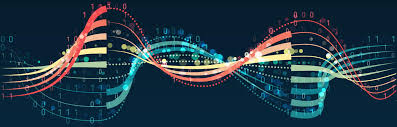

## Contents<a class="anchor" id="contents"></a>

- 1. [Introduction](#section1)
    - [Our natural experiment](#section1.1)
    - [Load the required packages](#section1.2)
    - [Load the data](#section1.3)
- 2. [Mapping the policy](#section2)
- 3. [Defining neighbours](#section3)
    - [Queen and rook neighbours](#section3.1)
    - [Nearest neighbours](#section3.2)
    - [Neighbours in time](#section3.3)
- 4. [Spatial weights](#section4)
- 5. [Spatial and temporal lags](#section5)
    - [The spatial lag](#section5.1)
    - [The temporal lag](#section5.2)
- 6. [Did the policy work? Difference-in-differences](#section6)
    - [Two tempting (but wrong) comparisons](#section6.1)
    - [Difference-in-differences by hand](#section6.2)
    - [Interactions](#section6.3)
    - [Difference-in-differences as a regression](#section6.4)
- 7. [Testing for spatial and temporal autocorrelation](#section7)
    - [Moran's I](#section7.1)
    - [Are our residuals autocorrelated?](#section7.2)
    - [What this means for our standard errors](#section7.3)
- 8. [The event study: one estimate per year](#section8)
- 9. [Exercise: did the policy spill over the border?](#exercise)
- 10. [Conclusion](#section10)

## 1. Introduction<a class="anchor" id="section1"></a>

So far in the course, every model we have run has used a single snapshot of our datazones. We have one smoking rate for each datazone, one measure of retailer density, one SIMD rank, and we compare datazones with each other. That has taken us a long way, but it leaves two things out that matter a great deal to geographers.

The first is <b><i>space</b></i>. Our datazones are not 1,600 unrelated observations. They sit next to each other on a map, and places that are close together tend to be alike. A deprived datazone is usually surrounded by other deprived datazones. So far we have quietly ignored this.

The second is <b><i>time</b></i>. A single snapshot can tell us that areas with more tobacco retailers have more smoking, but as we have discussed many times, that does not tell us that the retailers <b><i>cause</b></i> the smoking. One of the best ways of getting closer to cause and effect is to watch what happens to the same places <b><i>before and after</b></i> something changes.

In this practical we are going to bring both of these together. We will cover how to define which areas are <b><i>neighbours</b></i>, how to turn those neighbours into <b><i>spatial weights</b></i>, how to calculate <b><i>spatial and temporal lags</b></i>, and how to <b><i>test for spatial and temporal autocorrelation</b></i>. Along the way we will use all of this to answer a real (well, made-up but realistic!) policy question using an approach called <b><i>difference-in-differences</b></i>, which is one of the most widely used methods for evaluating policies.

### Our natural experiment<a class="anchor" id="section1.1"></a>

Here is the story. In 2016, two of the eight councils in our simulated Scotland, <b>Corriebeg</b> and <b>Fallinmuir</b>, introduced a cap on the number of tobacco retail licences. No new licences were issued, and when a shop selling tobacco closed or changed hands its licence was not renewed. The other six councils carried on as before.

The question we want to answer is: <b><i>did the cap reduce smoking during pregnancy?</b></i>

This is what is known as a <b><i>natural experiment</b></i>. Nobody randomly chose which councils got the policy (which is what would happen in a proper experiment) but the policy changed in some places and not in others at a known point in time. That gives us something to compare. As we will see, though, the comparison has to be made carefully!

<b>NOTE: the policy, like all of our data, is made up. Corriebeg and Fallinmuir are fictional councils and the effect of the cap was built into the simulated data. This means we actually know the right answer, which is very handy for checking whether our methods work...</b>

### Load the required packages<a class="anchor" id="section1.2"></a>

First, let's get the packages that we will need. There are a few new ones this week:

- `sf` (short for "simple features") lets R read and work with maps, so that each row of our data can have a boundary attached to it.
- `spdep` (short for "spatial dependence") does all the work with neighbours, weights and spatial autocorrelation.
- `broom` turns model output into a tidy data frame, which makes it easy to plot.
- `modelsummary`, which you met in the last practical, for putting models side by side.

`spdep` and `modelsummary` are not already installed, so we need to install them first, along with `sandwich`, which `modelsummary` uses to calculate the clustered standard errors in Section 7. Installing `spdep` will also install anything else it needs, including `sf`.

NOTE: This cell will take a while to complete so be patient! You only need to run it once.

In [ ]:
install.packages("spdep")
install.packages("modelsummary")
install.packages("sandwich")

And now let's load the packages. You may see some messages about objects being masked, but it's fine to ignore these.

In [ ]:
library(tidyverse)
library(sf)
library(spdep)
library(broom)
library(modelsummary)

### Load the data<a class="anchor" id="section1.3"></a>

We have three files this week:

- `datazones.geojson` holds the <b><i>boundaries</b></i> of our 1,600 datazones, along with the council each one is in. A GeoJSON file is just a common file format for storing maps.
- `datazone_info.csv` is a small table with the urban/rural classification and SIMD rank of each datazone.
- `smoking_panel.csv` holds the smoking rate in each datazone in <b><i>every year</b></i> from 2012 to 2019. Data like this, where the same areas are measured again and again over time, is known as <b><i>panel</b></i> or <b><i>longitudinal</b></i> data.

Let's read the boundaries first. Notice that we use `st_read` rather than `read_csv`.

In [ ]:
datazones <- st_read("datazones.geojson")

The output tells us that we have 1,600 features (datazones) and 2 fields (the columns `datazone` and `council`). It also tells us the type of geometry, polygons (shapes with boundaries), and the coordinate system, which is the British National Grid used by Ordnance Survey maps.

Let's look at the first few rows.

In [ ]:
print(head(datazones))

This looks just like the data frames we have been using all along, except that there is an extra column called `geometry`. Each row of this column holds the shape of one datazone (the long list of coordinates that make up its boundary). If you have used QGIS or ArcGIS Pro, this is exactly what you see when you open a layer's attribute table: one row per feature, with its shape stored alongside. Everything else we know about data frames still works, so we can join other data to it in exactly the same way as we did in the first practical (this is the same as a table join in GIS, i.e. Joins in a QGIS layer's properties or Add Join in ArcGIS Pro). Let's add the urban/rural and SIMD information.

In [ ]:
datazone_info <- read_csv("datazone_info.csv")

datazones <- datazones %>%
    left_join(datazone_info, by = "datazone")

print(head(datazones))

Now let's read in the smoking data and have a look at it.

In [ ]:
panel <- read_csv("smoking_panel.csv")

head(panel, 10)

Notice how this data is organised. Instead of one row per datazone, we now have one row per datazone <b><i>per year</b></i>. The first datazone appears in 8 rows, one for each year from 2012 to 2019, then the second datazone, and so on. That gives us 1,600 x 8 = 12,800 rows in total. This is called <b><i>long</b></i> format, and it is the shape that most longitudinal analysis in R expects. As in Practical 4, we have the number of `pregnant_women` and the number of `smokers` as well as the `smoking_rate` itself. There is also an `intermediate_zone` column. Intermediate zones are slightly bigger areas, each made up of a handful of neighbouring datazones. We will need these later on.

Finally, let's create two new variables that we will use all the way through the practical:

- `treated` is 1 if the datazone is in one of the two councils that introduced the cap, and 0 otherwise.
- `post` is 1 for the years after the cap came in (2016 onwards) and 0 for the years before.

Both of these are <b><i>dummy variables</b></i>, just like the ones R created for us automatically in Practical 4. The `%in%` operator checks whether each value is in a list.

In [ ]:
panel <- panel %>%
    mutate(treated = as.numeric(council %in% c("Corriebeg", "Fallinmuir")),
           post = as.numeric(year >= 2016))

#check how many rows are in each combination
panel %>%
  group_by(treated, post) %>%
  summarise(n = n())

So 400 of our datazones are in the treated councils (400 x 4 years = 1,600 rows before and 1,600 rows after) and 1,200 are not.

[Back to contents](#contents)

## 2. Mapping the policy<a class="anchor" id="section2"></a>

The first thing to do with any spatial data is to map it. Let's start by seeing where the treated councils are. `ggplot` can draw maps using `geom_sf`, which knows how to read the `geometry` column, so we don't need to tell it what goes on the x and y axes.

In [ ]:
datazones %>%
    mutate(cap = if_else(council %in% c("Corriebeg", "Fallinmuir"), "Licence cap from 2016", "No cap")) %>%
    ggplot() +
    geom_sf(aes(fill = cap), colour = NA) +
    labs(fill = NULL)

The two treated councils are the ones that contain our two cities. They look surprisingly small on the map, and that is because of the size of the datazones. Like real datazones, ours each contain roughly the same number of people, so they are tiny in the cities and very large in remote rural areas. A council full of city datazones covers very little land. The fact that the treated councils are the city councils is worth remembering, because it means the treated areas are not typical of the rest of the country: they are more urban and, as we know from earlier practicals, more deprived.

Now let's map the smoking rate itself. We have 8 years of data, so to keep things simple we will compare the last year before the cap (2015) with the last year we have (2019). To do this we join the smoking data for those two years onto the boundaries and then use `facet_wrap` to draw one map per year.

In [ ]:
datazones %>%
    left_join(filter(panel, year %in% c(2015, 2019)), by = c("datazone", "council")) %>%
    ggplot() +
    geom_sf(aes(fill = smoking_rate), colour = NA) +
    scale_fill_viridis_c() +
    facet_wrap(~year) +
    labs(fill = "Smoking rate (%)")

This kind of map, where each area is coloured according to the value of a variable, is called a <b><i>choropleth</b></i> map. It is what you would make with Graduated symbology in QGIS or ArcGIS Pro. The main difference is that GIS usually asks you to split the values into classes (equal interval, quantiles, natural breaks and so on), whereas here we have used a continuous colour scale. If you find these maps hard to read, you are not alone! They show one of the big problems with choropleth maps: our eye is drawn to the big areas, but the big areas are the rural datazones where hardly anyone lives. The city datazones, where most people live, are so small that they almost disappear. It is also very hard to see from these maps whether anything happened in the treated councils. Maps are great for seeing patterns across space, but not so good for seeing change over time. (Later in the practical we will use a statistic called Moran's I to tell us whether there are patterns in the map that our eyes can't easily pick out.)

For that we need a different plot. The code below calculates the mean smoking rate in each year, separately for the treated and untreated datazones, and plots them as two lines. The dashed line marks the point at which the cap came in.

In [ ]:
panel %>%
    group_by(treated, year) %>%
    summarise(mean_smoking = mean(smoking_rate)) %>%
    ggplot(aes(x = year, y = mean_smoking, colour = factor(treated))) +
    geom_line() +
    geom_point() +
    geom_vline(xintercept = 2015.5, linetype = "dashed") +
    scale_colour_discrete(labels = c("No cap", "Licence cap from 2016")) +
    labs(x = "Year", y = "Mean smoking rate (%)", colour = NULL)

Now we are getting somewhere. Have a careful look at this plot because it contains most of what this practical is about:

- Smoking is falling everywhere over time, whether or not there was a cap.
- The treated areas start off with <b><i>higher</b></i> smoking rates than the untreated ones (because they are more urban and more deprived).
- Before 2016, both lines are falling at a similar rate, with a gap of roughly 3 to 4 percentage points between them. The treated line is a bit bumpier, because it is the average of only 400 datazones rather than 1,200.
- After 2016, the gap closes. The treated areas fall faster than the untreated ones and, from 2018 onwards, are actually below them.

Keep this plot in mind. We will come back to it in Section 6.

[Back to contents](#contents)

## 3. Defining neighbours<a class="anchor" id="section3"></a>

Almost everything in spatial analysis starts with one simple question: <b><i>which areas are neighbours?</b></i>

It sounds obvious, but there is more than one sensible answer. Do two areas need to share a border, or is touching at a corner enough? What about two areas that don't touch at all but are only a few hundred metres apart? There is no single right answer, and the choice depends on your data and your research question. Let's look at the most common options.

### Queen and rook neighbours<a class="anchor" id="section3.1"></a>

The two most common definitions both use shared boundaries, and they take their names from chess:

- <b><i>Rook</b></i> neighbours must share an edge (a rook in chess can only move in straight lines).
- <b><i>Queen</b></i> neighbours can share an edge <b><i>or</b></i> just a single corner point (a queen can move in straight lines and diagonally).

On a chessboard the difference is big. A square in the middle of the board has 4 rook neighbours but 8 queen neighbours. Let's see what difference it makes with our datazones. The `poly2nb` function (short for "polygons to neighbours") works out which datazones are neighbours. The `card` function then counts how many neighbours each datazone has (it stands for "cardinality", which is just a fancy word for the number of things in a set).

In [ ]:
queen_nb <- poly2nb(datazones, queen = TRUE)
rook_nb <- poly2nb(datazones, queen = FALSE)

summary(card(queen_nb))
summary(card(rook_nb))

On average each datazone has just under 6 neighbours, whichever definition we use. The numbers are almost identical. Let's count exactly how many datazones end up with a different number of neighbours.

In [ ]:
sum(card(queen_nb) != card(rook_nb))

Only 12 out of 1,600! The reason is that real boundaries (unlike a chessboard) are irregular, so it is quite rare for areas to meet at just a single point. In practice, then, queen and rook neighbours are usually very similar for areas like datazones, but they can be quite different for regular grids (e.g. raster data or grid squares). We will use queen neighbours from here on, as they are the most common choice.

If you have used Select by Location in GIS, you have already found neighbours by hand. In ArcGIS Pro, selecting the features that "share a line segment with" a datazone gives you its rook neighbours, and the ones that "touch the boundary of" it gives you its queen neighbours. ArcGIS Pro also has a Generate Spatial Weights Matrix tool which offers the same choices as `spdep`: contiguity edges only (rook), contiguity edges and corners (queen), k nearest neighbours and fixed distance bands.

Let's look at what this actually means on the map. The code below picks one datazone, highlights it and its queen neighbours, and zooms in on that part of the map. In `spdep` the neighbours are stored as a list, with one element per datazone, so `queen_nb[[chosen]]` gives us the row numbers of the neighbours of our chosen datazone.

In [ ]:
chosen <- 245

queen_nb[[chosen]]

datazones %>%
    mutate(role = case_when(row_number() == chosen ~ "Chosen datazone",
                            row_number() %in% queen_nb[[chosen]] ~ "Neighbour",
                            TRUE ~ "Other")) %>%
    ggplot() +
    geom_sf(aes(fill = role), colour = "white") +
    coord_sf(xlim = st_bbox(datazones[queen_nb[[chosen]], ])[c("xmin", "xmax")],
             ylim = st_bbox(datazones[queen_nb[[chosen]], ])[c("ymin", "ymax")]) +
    scale_fill_manual(values = c("darkorange", "steelblue", "grey85")) +
    labs(fill = NULL)

Try changing the number in `chosen <- 245` to look at a few other datazones (any number from 1 to 1600 will work). You will find that datazones in the cities are small and so are their neighbours, while some rural datazones are huge.

If you want to explore this more, have a go with the <b>neighbours explorer</b> (there's a link to it below). You can click on any datazone and switch between queen, rook and nearest neighbours, and it also shows you the weights and lags that we are about to cover in the next two sections.

https://tc245.github.io/data-science-apps/neighbours/

### Nearest neighbours<a class="anchor" id="section3.2"></a>

Neighbours don't have to share a boundary at all. Another common approach is to use the <b><i>k nearest neighbours</b></i>: for every area, find the k areas whose centres are closest to it. This is often used when areas don't touch each other (e.g. islands) or when the data are points rather than areas (e.g. the locations of individual shops).

To do this we first need the centre point, or <b><i>centroid</b></i>, of each datazone, which `st_centroid` calculates for us (the same as the Centroids tool in QGIS or Feature To Point in ArcGIS Pro). Then `knearneigh` finds the 6 nearest centroids, and `knn2nb` turns the result into the same kind of neighbour list as before.

In [ ]:
centroids <- st_centroid(st_geometry(datazones))

knn_nb <- knn2nb(knearneigh(centroids, k = 6))

summary(card(knn_nb))

Not surprisingly, every datazone now has exactly 6 neighbours. That is one advantage of this approach: every area gets the same number of neighbours, which can be helpful when some areas would otherwise have very few. The disadvantage is that "nearest" does not always mean "connected". For a big rural datazone, the 6 nearest centroids could be a long way away, and it might not actually touch some of them.

There is one other odd thing about nearest neighbours. Let's check whether they are <b><i>symmetric</b></i>, in other words, if A is one of B's neighbours, is B always one of A's neighbours?

In [ ]:
is.symmetric.nb(queen_nb)
is.symmetric.nb(knn_nb)

Queen neighbours are always symmetric (if I share a boundary with you then you share it with me!). Nearest neighbours are not. A small city datazone might be one of the 6 nearest neighbours of a datazone next door, but have 6 even closer neighbours of its own. This doesn't stop us using them, but it is worth knowing about.

Another option you might come across is <b><i>distance bands</b></i>, where any areas within a certain distance of each other (e.g. 5km) count as neighbours. These are created with the `dnearneigh` function. We won't use them here, but they work in a very similar way.

### Neighbours in time<a class="anchor" id="section3.3"></a>

So far all our neighbours have been neighbours in <b><i>space</b></i>. But we also have data over time, and here the idea of a neighbour is much simpler. Time only goes in one direction, so the obvious neighbour of 2017 is 2016, the year before. That is it! There is no need for queen or rook or nearest neighbour rules. We will make use of this in Section 5.

[Back to contents](#contents)

## 4. Spatial weights<a class="anchor" id="section4"></a>

Knowing which areas are neighbours is the first step. The second step is to decide how much each neighbour should <b><i>count</b></i>. These are known as <b><i>spatial weights</b></i>. The `nb2listw` function (short for "neighbours to list of weights") creates them from our neighbour list. The `style` argument controls how the weights are calculated, and there are two that you need to know about:

- `style = "B"` creates <b><i>binary</b></i> weights. Every neighbour gets a weight of 1 and every other area gets a weight of 0.
- `style = "W"` creates <b><i>row-standardised</b></i> weights. Each area's weights are divided by its number of neighbours, so that they add up to 1. If an area has 4 neighbours, each gets a weight of 1/4 = 0.25. If it has 5, each gets 1/5 = 0.2.

Let's create both and look at the weights for our chosen datazone from before.

In [ ]:
weights_binary <- nb2listw(queen_nb, style = "B")
weights_rowstd <- nb2listw(queen_nb, style = "W")

weights_binary$weights[[chosen]]
weights_rowstd$weights[[chosen]]

Our chosen datazone has 7 neighbours, so with binary weights each gets a weight of 1 and with row-standardised weights each gets 1/7 = 0.143.

Why does this matter? Think about what happens when we multiply each neighbour's value by its weight and add them up. With binary weights, we get the <b><i>total</b></i> of the neighbours' values, so an area with 10 neighbours will get a much bigger number than an area with 3 neighbours, even if their neighbours are all identical. With row-standardised weights we get the <b><i>average</b></i> of the neighbours' values, which can be compared fairly between areas with different numbers of neighbours. That is why row-standardised weights are by far the most common choice, and the ones we will use for the rest of the practical. (The Generate Spatial Weights Matrix tool in ArcGIS Pro has a Row Standardization tick box which does exactly this.)

One more thing. You will often see spatial weights described as a <b><i>matrix</b></i>, usually called <b><i>W</b></i>. This is just a big table with one row and one column for every area (so 1,600 x 1,600 for us), where the cell in row i and column j holds the weight that area j gets when we are looking at area i. Most of the cells are zero, because most areas are not neighbours. `spdep` stores only the non-zero values (which is what we printed above) because the full matrix would be huge, but the idea is the same.

[Back to contents](#contents)

## 5. Spatial and temporal lags<a class="anchor" id="section5"></a>

### The spatial lag<a class="anchor" id="section5.1"></a>

We now have everything we need to calculate a <b><i>spatial lag</b></i>. The spatial lag of a variable is simply the weighted sum of that variable in each area's neighbours. With row-standardised weights, it is the <b><i>average value among an area's neighbours</b></i>.

For example, if a datazone has three neighbours with smoking rates of 10%, 15% and 20%, then its spatial lag is (10 + 15 + 20) / 3 = 15%. Notice that the spatial lag doesn't include the datazone's own value at all. It tells us about the surroundings, not the place itself.

Let's calculate the spatial lag of the smoking rate in 2015. First we need to join the 2015 smoking data onto our boundaries. Then we use `lag.listw` to calculate the lag.

<b>NOTE: the order of the rows really matters here. The neighbour list was created from the `datazones` object, so the values we give `lag.listw` must be in exactly the same order. `left_join` keeps the rows of the first object in their original order, which is why we start from `datazones` and join the smoking data onto it, rather than the other way round.</b>

In [ ]:
map_2015 <- datazones %>%
    left_join(filter(panel, year == 2015), by = c("datazone", "council"))

map_2015 <- map_2015 %>%
    mutate(smoking_lag = lag.listw(weights_rowstd, smoking_rate))

map_2015 %>%
    st_drop_geometry() %>%
    select(datazone, smoking_rate, smoking_lag) %>%
    head()

(`st_drop_geometry` just removes the long geometry column so that the table is easier to read.)

Let's check the lag for our chosen datazone by hand to make sure we know what it is doing. We take the smoking rates of its neighbours and calculate their mean.

In [ ]:
mean(map_2015$smoking_rate[queen_nb[[chosen]]])

map_2015$smoking_lag[chosen]

They are the same. Now let's map the smoking rate and its spatial lag side by side. To do this with `facet_wrap` we first need to put the two variables into one column using `pivot_longer`.

In [ ]:
map_2015 %>%
    select(smoking_rate, smoking_lag) %>%
    pivot_longer(c(smoking_rate, smoking_lag), names_to = "measure", values_to = "value") %>%
    ggplot() +
    geom_sf(aes(fill = value), colour = NA) +
    scale_fill_viridis_c() +
    facet_wrap(~measure) +
    labs(fill = "Smoking rate (%)")

The spatial lag map (on the left) looks like a smoothed version of the original. Because each value is an average of several neighbours, the random ups and downs of individual datazones get evened out and the broad pattern of high and low areas stands out more clearly. This is one of the main uses of the spatial lag: it shows us what each area's surroundings are like.

There isn't usually a single button for the spatial lag in GIS software, but you can calculate it in the QGIS Field Calculator with `array_mean(overlay_touches('datazones', "smoking_rate"))`. This gives each datazone the mean smoking rate of the datazones it touches, in other words its queen neighbours with row-standardised weights.

### The temporal lag<a class="anchor" id="section5.2"></a>

The <b><i>temporal lag</b></i> is the same idea but for time. The temporal lag of a variable is its value in the <b><i>previous</b></i> time period, which in our case is the year before. Remember that in time there is only one neighbour, so there is no need for weights (or, if you like, the year before gets a weight of 1 and every other year gets 0).

The `lag` function in the tidyverse does this for us. We need to be careful though. We want the previous year for the <b><i>same datazone</b></i>, so we must:

- sort the data by datazone and year using `arrange`, so that the years are in the right order, and
- use `group_by(datazone)` so that the first year of one datazone doesn't pick up the last year of the datazone before it.

In [ ]:
panel <- panel %>%
    arrange(datazone, year) %>%
    group_by(datazone) %>%
    mutate(smoking_last_year = lag(smoking_rate)) %>%
    ungroup()

panel %>%
    select(datazone, year, smoking_rate, smoking_last_year) %>%
    head(10)

Look at how the values move down one row. The smoking rate for 2012 becomes the "last year" value for 2013, and so on. The first year for each datazone has a missing value (`NA`) because we don't have any data for 2011. The first year of the second datazone is also `NA`, which tells us that `group_by` has done its job.

So how similar is each year to the year before? Let's plot this year's smoking rate against last year's and calculate the correlation.

In [ ]:
ggplot(panel, aes(x = smoking_last_year, y = smoking_rate)) +
    geom_point(alpha = 0.1) +
    geom_smooth(method = lm, se = FALSE) +
    labs(x = "Smoking rate last year (%)", y = "Smoking rate this year (%)")

cor(panel$smoking_rate, panel$smoking_last_year, use = "complete.obs")

(R warns that it has removed 1,600 rows. Don't worry, these are just the 2012 rows, which have no previous year to plot.)

There is a strong positive correlation (about 0.6). Datazones with high smoking rates one year tend to have high rates the next year too, which is hardly surprising. Places don't change completely from one year to the next.

That might seem obvious, but it has an important consequence. It means that our 12,800 rows are not really 12,800 independent pieces of information. Eight years of data from the same datazone tell us less than eight different datazones would, because each year mostly repeats what we already knew from the year before. The same goes for space: a datazone and its neighbours tend to be alike, so they partly repeat each other too. Keep this in mind, because it comes back to bite us in Section 7!

[Back to contents](#contents)

## 6. Did the policy work? Difference-in-differences<a class="anchor" id="section6"></a>

Ok, let's get back to our policy question. Did the licence cap reduce smoking during pregnancy?

### Two tempting (but wrong) comparisons<a class="anchor" id="section6.1"></a>

There are two obvious ways you might try to answer this. Both are used all the time, and both are wrong. Let's try them anyway, because seeing <b><i>why</b></i> they are wrong is the key to understanding the right approach.

<b>Comparison 1: before and after.</b> The simplest thing to do is to look at the treated areas only and compare smoking before and after the cap came in.

In [ ]:
panel %>%
    filter(treated == 1) %>%
    group_by(post) %>%
    summarise(mean_smoking = mean(smoking_rate))

Smoking in the treated councils fell from 20.4% to 14.9%, a drop of 5.5 percentage points. Great, the policy worked! Or did it? Remember our plot from Section 2. Smoking was falling <b><i>everywhere</b></i>, including in the councils that didn't have a cap. Some (perhaps most) of this drop would have happened anyway. A simple before and after comparison mixes up the effect of the policy with everything else that changed over the same period.

<b>Comparison 2: treated versus untreated.</b> Ok, so let's compare the treated and untreated areas instead, after the cap came in.

In [ ]:
panel %>%
    filter(post == 1) %>%
    group_by(treated) %>%
    summarise(mean_smoking = mean(smoking_rate))

After 2016, smoking in the treated councils (14.9%) was almost exactly the same as in the untreated ones (14.8%), and actually very slightly higher. So the policy did nothing at all? Not so fast. Remember that the treated councils are the ones containing the cities, which are more deprived and had <b><i>higher</b></i> smoking rates to start with. This comparison mixes up the effect of the policy with all of the other differences between the places that had the policy and the places that didn't. This is exactly the problem of <b><i>confounding</b></i> that we have been talking about since Practical 2.

### Difference-in-differences by hand<a class="anchor" id="section6.2"></a>

The solution is to combine the two comparisons. The idea is this:

1. The untreated areas show us how much smoking changed over time <b><i>without</b></i> the policy.
2. If the treated areas had not had the policy, we assume that their smoking rates would have changed by the <b><i>same amount</b></i>.
3. So the effect of the policy is the change in the treated areas <b><i>minus</b></i> the change in the untreated areas.

Because we take the <b><i>difference</b></i> between two <b><i>differences</b></i> (before and after), this approach is called <b><i>difference-in-differences</b></i> (or DiD for short).

The best way to see this is with a 2 x 2 table of means: treated and untreated, before and after.

In [ ]:
did_table <- panel %>%
    group_by(treated, post) %>%
    summarise(mean_smoking = mean(smoking_rate)) %>%
    pivot_wider(names_from = post, values_from = mean_smoking, names_prefix = "post_") %>%
    mutate(change = post_1 - post_0)

did_table

Each row now shows the mean before (`post_0`), the mean after (`post_1`) and the change between them. The untreated areas fell by 2.1 percentage points. That is our estimate of what would have happened without the policy. The treated areas fell by 5.5 percentage points. The difference between these two changes is our difference-in-differences.

In [ ]:
did_table$change[2] - did_table$change[1]

So the cap reduced smoking by about 3.4 percentage points over the four years after it came in. Notice that this is smaller than comparison 1 (because we have taken out the general fall in smoking) but bigger than comparison 2 (because we no longer compare places that were different to start with).

Why does this get rid of the confounding? Because we are comparing each group <b><i>with itself</b></i>. All of the things that make the treated areas different from the untreated ones, like being more urban and more deprived, are there both before and after. As long as they stay the same over time, they cancel out when we take the change.

But this only works if one important assumption holds, which is known as the <b><i>parallel trends</b></i> assumption: without the policy, the treated and untreated areas would have followed the <b><i>same trend</b></i> over time. They can start at different levels (that is fine) but they must move in parallel. We can never check this directly for the years after 2016, because we can't see what would have happened without the policy. What we <b><i>can</b></i> do is check whether the trends were parallel <b><i>before</b></i> the policy came in. Go back and look at the plot at the end of Section 2: before 2016, the two lines fall at a similar rate with a roughly constant gap. That is reassuring. We will check this more formally in Section 8.

To see what happens when the parallel trends assumption fails, have a go with the <b>difference-in-differences builder</b> (link below). You can build the estimate step by step, change the size of the effect, and see how the answer goes wrong when the two groups were on different trends to start with.

https://tc245.github.io/data-science-apps/did/

### Interactions<a class="anchor" id="section6.3"></a>

Calculating the difference-in-differences by hand is a good way to understand it, but in practice we want to do it with a regression model. That way we get standard errors and confidence intervals, and we can add other variables to the model if we need to. To do this we need one new idea: the <b><i>interaction</b></i>.

In all of the models we have run so far, the effect of each variable has been the same regardless of the values of the other variables. When we ran `lm(smoking_rate ~ retailers_adj + simd_quintile)` in Practical 4, the model assumed that one extra retailer had the same effect in the most deprived areas as in the least deprived areas. The variables just add up.

But sometimes the effect of one variable <b><i>depends</b></i> on the value of another. That is exactly our situation. We think the change from before to after (`post`) was <b><i>different</b></i> in the treated areas than in the untreated ones. When the effect of one variable depends on another, we say that they <b><i>interact</b></i>.

In R we add an interaction by putting a `*` between two variables instead of a `+`. Writing `treated * post` is just a shorthand that asks for three things at once:

- `treated`, the effect of being in a treated council,
- `post`, the effect of being in the years after 2016, and
- `treated:post`, the <b><i>interaction</b></i>, which is created by multiplying the two dummy variables together. It is 1 only for treated areas in the years after the cap, and 0 for everything else.

Let's see what the interaction variable looks like for a few rows.

In [ ]:
panel %>%
    mutate(treated_x_post = treated * post) %>%
    group_by(treated, post) %>%
    summarise(treated_x_post = mean(treated_x_post))

As you can see, the interaction is 1 for only one of the four groups: the treated areas after the cap. That is how it picks out the extra change that happened only in the treated areas.

### Difference-in-differences as a regression<a class="anchor" id="section6.4"></a>

Now let's run the model.

In [ ]:
did_model <- lm(smoking_rate ~ treated * post, data = panel, na.action = na.exclude)

summary(did_model)

Look at the coefficients and compare them with the 2 x 2 table from earlier. Each one corresponds to one of the numbers we calculated by hand:

- The `(Intercept)` (16.9) is the mean for the untreated areas before the cap (`treated = 0` and `post = 0`). This is our starting point, just like the reference category in Practical 4.
- The `treated` coefficient (3.5) is the gap between the treated and untreated areas before the cap. It is positive because the treated areas had higher smoking rates to start with.
- The `post` coefficient (-2.1) is the change over time in the untreated areas, our estimate of what would have happened anyway.
- The `treated:post` coefficient (-3.4) is the difference-in-differences: the extra change in the treated areas over and above the change everywhere else. It is exactly the same number we calculated by hand!

So the model tells us that the licence cap reduced smoking rates by 3.4 percentage points, and the p-value suggests this is very unlikely to be due to chance. The 95% confidence interval for this effect is:

In [ ]:
confint(did_model)

Before we get too excited, though, there is a problem with these standard errors (and therefore with the p-values and confidence intervals). We will look at what it is in the next section.

[Back to contents](#contents)

## 7. Testing for spatial and temporal autocorrelation<a class="anchor" id="section7"></a>

Way back in Practical 3 we went through the assumptions of linear regression. One of them was that the observations (or more precisely, the residuals) are <b><i>independent</b></i> of each other. In other words, knowing the residual for one observation should tell you nothing about the residual for any other observation.

When observations close together in space are more alike than observations far apart, we call this <b><i>spatial autocorrelation</b></i>. When observations close together in time are more alike than observations far apart in time, we call it <b><i>temporal autocorrelation</b></i> (or serial correlation). "Auto" just means "self": the variable is correlated with itself in nearby places or times. We have already seen signs of both, so let's test for them properly.

### Moran's I<a class="anchor" id="section7.1"></a>

The most common test for spatial autocorrelation is <b><i>Moran's I</b></i>. It works a lot like a correlation coefficient, but instead of correlating two different variables, it correlates a variable with its own spatial lag. Roughly:

- A value close to <b><i>+1</b></i> means strong positive spatial autocorrelation: high values sit next to high values and low values next to low values (clustering).
- A value close to <b><i>0</b></i> means no spatial autocorrelation: values are scattered at random across the map.
- A <b><i>negative</b></i> value means that high values tend to sit next to low values, like the black and white squares on a chessboard. This is quite rare in practice.

The easiest way to understand it is with a plot of each datazone's smoking rate against its spatial lag (the average of its neighbours), which is known as a <b><i>Moran scatterplot</b></i>.

In [ ]:
ggplot(map_2015, aes(x = smoking_rate, y = smoking_lag)) +
    geom_point(alpha = 0.3) +
    geom_smooth(method = lm, se = FALSE) +
    labs(x = "Smoking rate in 2015 (%)", y = "Average smoking rate of neighbours (%)")

The line slopes upwards: datazones with higher smoking rates tend to have neighbours with higher smoking rates. In fact, when we use row-standardised weights, Moran's I is exactly the slope of this line.

So how do we know whether this is more than we would expect by chance? Imagine taking all 1,600 smoking rates, shuffling them up, and dealing them out randomly across the map. In the shuffled map there can't be any real spatial pattern, so whatever Moran's I we get is just down to chance. If we do this lots of times (say 999 times), we get a good idea of the range of values that chance alone can produce. If the real Moran's I is bigger than nearly all of the shuffled ones, we can be confident that the clustering is real. This is called a <b><i>permutation test</b></i> and the `moran.mc` function does it for us (the "mc" stands for "Monte Carlo", which is the general name for methods that use lots of random simulations).

Because it uses random shuffles, we use `set.seed` first so that we get the same answer every time we run it.

In [ ]:
set.seed(2026)

moran.mc(map_2015$smoking_rate, weights_rowstd, nsim = 999)

The `statistic` is Moran's I, which is 0.22. That might not sound like much, but the `observed rank` tells us that it is bigger than all 999 of the shuffled values, so the p-value is 0.001 (1 in 1,000, the smallest possible with 999 shuffles). Smoking rates are clearly clustered across space.

If you have used the Spatial Autocorrelation (Global Moran's I) tool in ArcGIS Pro, it gives the same Moran's I as long as you choose the same neighbours and weights (contiguity edges and corners, with row standardisation). It also gives a z-score and a p-value, but it calculates the p-value from a formula rather than by shuffling, so it won't match ours exactly. You may also have come across Hot Spot Analysis or Cluster and Outlier Analysis, which are <b><i>local</b></i> versions of the same idea: instead of one number for the whole map, they tell you where the clusters are.

You can watch this shuffling happen in the <b>autocorrelation explorer</b> (link below). It builds up the shuffled values one at a time so you can see where the real value falls, and it has a version for time as well as space.

https://tc245.github.io/data-science-apps/autocorrelation/

### Are our residuals autocorrelated?<a class="anchor" id="section7.2"></a>

Of course, smoking rates being clustered isn't necessarily a problem in itself. We would expect them to be clustered, because deprivation is clustered. What matters for our regression is whether the <b><i>residuals</b></i> are autocorrelated, in other words whether the bits of smoking that our model <b><i>can't</b></i> explain are clustered too.

Let's start by adding the residuals from our difference-in-differences model to the data. We will also calculate the residual from the year before (the temporal lag of the residual) while we are at it.

In [ ]:
panel <- panel %>%
    mutate(residual = residuals(did_model)) %>%
    group_by(datazone) %>%
    mutate(residual_last_year = lag(residual)) %>%
    ungroup()

First, space. We have 8 residuals for every datazone (one per year), but Moran's I needs one value per datazone. So we take the average residual for each datazone and join it to the boundaries, in the same way as before, and then run the test.

In [ ]:
residual_map <- datazones %>%
    left_join(panel %>%
                group_by(datazone) %>%
                summarise(mean_residual = mean(residual)),
              by = "datazone")

set.seed(2026)

moran.mc(residual_map$mean_residual, weights_rowstd, nsim = 999)

Moran's I for the residuals is 0.32 and the p-value is 0.001 again, so the residuals are strongly spatially autocorrelated. (It is even higher than for the smoking rates themselves, because averaging over 8 years smooths out a lot of the random noise.) Let's map them to see what this looks like.

In [ ]:
ggplot(residual_map) +
    geom_sf(aes(fill = mean_residual), colour = NA) +
    scale_fill_gradient2() +
    labs(fill = "Mean residual")

Blue areas have higher smoking rates than our model predicts and red areas have lower ones. You can see that they are not scattered randomly. There are clear patches of blue and red. That makes sense: our model only knows whether an area is treated and whether it is before or after 2016. It doesn't know anything about deprivation, so the deprived areas (which are clustered together) end up with large positive residuals.

Now time. To test for temporal autocorrelation we can simply calculate the correlation between each residual and the residual for the same datazone in the year before. `cor.test` gives us the correlation along with a p-value.

In [ ]:
cor.test(panel$residual, panel$residual_last_year)

The correlation is 0.57 and highly significant. So if a datazone's smoking rate is higher than the model predicts in one year, it is very likely to be higher than predicted the next year as well. Our residuals are autocorrelated in both space and time.

### What this means for our standard errors<a class="anchor" id="section7.3"></a>

Why does this matter? When `lm` calculates standard errors, it assumes that every one of our 12,800 rows is an independent piece of information. We have just seen that they aren't. Rows from the same datazone in different years are related, and so are rows from neighbouring datazones. If we pretend they are independent, our standard errors will be wrong.

The usual fix is to use what are called <b><i>clustered standard errors</b></i>. We tell R which rows belong together in a group (a "cluster"), and it allows the residuals within each cluster to be correlated with each other when it calculates the standard errors. The coefficients themselves don't change at all, only the standard errors.

What should the clusters be? Each cluster needs to contain all of the rows that might be related. We will use the <b><i>intermediate zones</b></i>. Each one contains a few neighbouring datazones, so a cluster contains every year of data from a small group of neighbouring datazones. That covers the correlation over time and some of the correlation between neighbours. Why not use something bigger, like councils? Because we only have 8 councils, and clustered standard errors are unreliable when there are only a handful of clusters (the usual rule of thumb is to have at least 30 to 50).

The `modelsummary` package from the last practical makes this easy. The `vcov` argument tells it how to calculate the standard errors. Here we show the same model twice, once with the ordinary ("classical") standard errors and once clustered by intermediate zone.

In [ ]:
modelsummary(list("Classical" = did_model, "Clustered" = did_model),
             vcov = list("classical", ~intermediate_zone),
             gof_map = c("nobs"))

The coefficients are identical in the two columns, but the standard errors (in brackets) are not. Look at two of them in particular:

- The standard error for `treated` gets much bigger (from 0.34 to 0.90). The `treated` coefficient compares <b><i>different</b></i> areas with each other. The classical standard error treated the 8 years of each datazone as 8 separate datazones, which made us look far more certain about this comparison than we really were.
- The standard error for `treated × post`, our difference-in-differences, actually gets <b><i>smaller</b></i> (from 0.48 to 0.35). This might seem surprising, but it is one of the reasons difference-in-differences is so popular. The DiD compares each area <b><i>with itself</b></i> before and after. The things that make a datazone persistently higher or lower than average (the clustered residuals we just mapped) cancel out in that comparison, and the clustered standard errors take this into account, whereas the classical ones don't.

So in this case the correction happens to make us more confident about the policy effect, but it can easily go the other way. In real data, it is very common for clustered standard errors on a difference-in-differences to be much bigger than the classical ones (e.g. when areas drift up and down over several years). Either way, the classical standard errors were wrong, because our data are not independent. Whenever you use panel data or spatial data, you should think about how your observations are related and use clustered standard errors (or another method that allows for autocorrelation).

[Back to contents](#contents)

## 8. The event study: one estimate per year<a class="anchor" id="section8"></a>

Our difference-in-differences gives us a single number: the average effect of the cap over all four years after it came in. That is useful, but it hides two things we might want to know:

1. <b>Were the trends really parallel before 2016?</b> We have only eyeballed this from the plot in Section 2.
2. <b>Did the effect happen all at once, or did it build up over time?</b> A licence cap works slowly, as shops close one by one, so we might expect the effect to grow.

An <b><i>event study</b></i> answers both questions. Instead of splitting the years into just "before" and "after", we let every year have its own estimate. Each estimate compares the gap between the treated and untreated areas in that year with the gap in a <b><i>reference year</b></i>. We use 2015, the last year before the cap.

This is exactly the same model as before, except that we replace `post` with `year` as a factor variable, and use `relevel` to make 2015 the reference category, just as we did with the SIMD quintiles in Practical 4.

In [ ]:
panel <- panel %>%
    mutate(year_f = relevel(factor(year), ref = "2015"))

event_model <- lm(smoking_rate ~ treated * year_f, data = panel, na.action = na.exclude)

summary(event_model)

That is a lot of coefficients! The ones we are interested in are the interactions at the bottom (`treated:year_f2012`, `treated:year_f2013` and so on). Each one is a mini difference-in-differences: how much bigger or smaller the gap between treated and untreated areas was in that year, compared with the gap in 2015.

These are much easier to understand as a plot. The `tidy` function from the `broom` package turns the model output into a data frame, with the confidence intervals if we ask for them. We then keep just the interaction terms (`str_detect` finds the rows whose names contain `treated:`), pull the year out of their names with `parse_number`, and add a row for 2015, which is 0 by definition because it is the reference year.

In [ ]:
event_estimates <- tidy(event_model, conf.int = TRUE) %>%
    filter(str_detect(term, "treated:")) %>%
    mutate(year = parse_number(term)) %>%
    select(year, estimate, conf.low, conf.high) %>%
    bind_rows(tibble(year = 2015, estimate = 0, conf.low = 0, conf.high = 0))

event_estimates

In [ ]:
ggplot(event_estimates, aes(x = year, y = estimate)) +
    geom_hline(yintercept = 0) +
    geom_vline(xintercept = 2015.5, linetype = "dashed") +
    geom_pointrange(aes(ymin = conf.low, ymax = conf.high)) +
    labs(x = "Year", y = "Difference compared with 2015 (percentage points)")

Let's read this plot from left to right.

<b>Before 2016</b> the estimates bounce around zero and every confidence interval crosses the zero line. In other words, in the years before the cap, the gap between the treated and untreated areas was no different from the gap in 2015. This is the evidence for parallel trends that we couldn't get from the single DiD estimate. If the treated areas had already been falling faster before 2016, we would see the estimates sloping downwards on the left-hand side of the plot, and we should then be very suspicious of any "effect" after 2016.

<b>After 2016</b> the estimates drop below zero and get steadily bigger: about 2.6 percentage points in 2016, rising to about 4.8 by 2019. So the effect of the cap built up over time, just as we would expect from a policy that works by gradually reducing the number of shops. The single DiD estimate of 3.4 was an average of these four years, which is why it is smaller than the effect by the end.

One more note. These standard errors are the classical ones, which we now know are not quite right. To keep things simple we haven't clustered them here, but you could do so with `modelsummary` in exactly the same way as before.

The <b>difference-in-differences builder</b> has an event study step too, so you can see what this plot looks like when the parallel trends assumption fails.

[Back to contents](#contents)

## 9. Exercise: did the policy spill over the border?<a class="anchor" id="exercise"></a>

There is one more thing to worry about with our natural experiment. People don't stay inside council boundaries! If you live in an untreated datazone right on the edge of Corriebeg, the cap might mean fewer shops selling tobacco just over the border, where you might well do some of your shopping. So the cap might also have reduced smoking in the untreated datazones next to the treated councils. This is known as a <b><i>spillover</b></i>.

If there was a spillover, it causes a problem for our difference-in-differences. We have been using all of the untreated areas to show us what would have happened without the policy. If some of them were affected by the policy too, they will have fallen faster than they otherwise would, making the policy look less effective than it really was.

This is where our neighbours come in. The code below finds the untreated datazones that are queen neighbours of at least one treated datazone. We will call these the <b><i>border ring</b></i>. For every datazone, `sapply` looks at its queen neighbours (`queen_nb`) and checks whether `any` of them are treated. It then adds a `border_ring` variable to the panel data. (In GIS you could do the same thing with Select by Location: select the datazones that touch the boundary of the treated councils, then remove the treated datazones from the selection.)

In [ ]:
treated_area <- datazones$council %in% c("Corriebeg", "Fallinmuir")

touches_treated <- sapply(queen_nb, function(neighbours) any(treated_area[neighbours]))

ring_datazones <- datazones$datazone[!treated_area & touches_treated]

length(ring_datazones)

panel <- panel %>%
    mutate(border_ring = as.numeric(datazone %in% ring_datazones))

1. Make a map showing the treated datazones, the border ring and all of the other datazones (hint: look back at how we made the map of our chosen datazone and its neighbours in Section 3).


2. Re-run the difference-in-differences model from Section 6, but this time <b><i>leave out</b></i> the border ring datazones (use `filter`). How does the estimated effect of the cap change? Why do you think this is?


3. Now look for the spillover directly. Leave out the <b><i>treated</b></i> datazones, and run a difference-in-differences model comparing the border ring with the rest of the untreated datazones (i.e. use `border_ring * post` instead of `treated * post`). Is there evidence of a spillover? How big is it compared with the effect in the treated councils?


4. Repeat question 3 with clustered standard errors (clustered by intermediate zone). Does your conclusion change?


5. (Extra) Run an event study for the border ring, in the same way as Section 8. Do the trends look parallel before 2016?

Enter your answers into the empty code cell below. Once you have had a go, the solutions are in the hidden cell underneath it: click on the three dots (`...`) to reveal the code.

In [ ]:
#code solutions
#1.
datazones %>%
    mutate(group = case_when(treated_area ~ "Treated council",
                             datazone %in% ring_datazones ~ "Border ring",
                             TRUE ~ "Other untreated")) %>%
    ggplot() +
    geom_sf(aes(fill = group), colour = NA) +
    labs(fill = NULL)

#2.
did_no_ring <- lm(smoking_rate ~ treated * post,
                  data = filter(panel, border_ring == 0),
                  na.action = na.exclude)
summary(did_no_ring)
#The effect gets a bit bigger (more negative). The border ring was also affected by the cap,
#so including it in the comparison group made the comparison group fall faster than it would have
#done without the policy, which made the policy look less effective than it was.

#3.
spillover_model <- lm(smoking_rate ~ border_ring * post,
                      data = filter(panel, treated == 0),
                      na.action = na.exclude)
summary(spillover_model)
#The border_ring:post coefficient is negative and statistically significant: smoking fell faster
#in the border ring than in the other untreated datazones after 2016. It is smaller than the effect
#in the treated councils, which makes sense as only some of the people living there are affected.

#4.
modelsummary(list("Classical" = spillover_model, "Clustered" = spillover_model),
             vcov = list("classical", ~intermediate_zone),
             gof_map = c("nobs"))
#The standard error for the spillover gets smaller, as it did for the main model, so the conclusion
#is the same (if anything the evidence is stronger).

#5.
ring_event_model <- lm(smoking_rate ~ border_ring * year_f,
                       data = filter(panel, treated == 0),
                       na.action = na.exclude)

tidy(ring_event_model, conf.int = TRUE) %>%
    filter(str_detect(term, "border_ring:")) %>%
    mutate(year = parse_number(term)) %>%
    select(year, estimate, conf.low, conf.high) %>%
    bind_rows(tibble(year = 2015, estimate = 0, conf.low = 0, conf.high = 0)) %>%
    ggplot(aes(x = year, y = estimate)) +
    geom_hline(yintercept = 0) +
    geom_vline(xintercept = 2015.5, linetype = "dashed") +
    geom_pointrange(aes(ymin = conf.low, ymax = conf.high)) +
    labs(x = "Year", y = "Difference compared with 2015 (percentage points)")

[Back to contents](#contents)

## 10. Conclusion<a class="anchor" id="section10"></a>

We have covered a lot today! You should now be able to define neighbours in space (queen, rook and nearest neighbours) and in time, turn them into spatial weights, calculate spatial and temporal lags, and test for spatial and temporal autocorrelation using Moran's I and the correlation between residuals over time. You have also used all of these to evaluate a policy using difference-in-differences and an event study.

A few things to bear in mind if you want to use these methods in your own projects:

- <b>Difference-in-differences is only as good as the parallel trends assumption.</b> Always plot the trends and, if you can, run an event study to check the years before the policy. Also think hard about whether anything <b><i>else</b></i> changed in the treated areas at the same time as the policy, because DiD can't tell the two apart.
- <b>Think about your comparison group.</b> As the exercise showed, if the comparison areas were affected by the policy too, your estimate will be wrong. Neighbours are a very useful tool for finding areas that might be affected.
- <b>Think about how your observations are related.</b> With spatial or panel data, they almost never are independent, so always test for autocorrelation and use clustered standard errors (or something similar).
- <b>In real data, policies are often messier.</b> Different areas might introduce a policy in different years, or turn it on and off again. There are more advanced versions of difference-in-differences for these situations, and more advanced spatial models (e.g. spatial lag and spatial error models) that build the spatial weights directly into the regression. They are beyond this course, but everything you have learned today is the foundation for them.

[Back to contents](#contents)